<a href="https://colab.research.google.com/github/2952342H/Effect-of-Electrode-Density-on-Rate-Performance-in-Li-rich-Cathodes/blob/main/POSTER.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Please upload all 8 battery Excel files, 6 SEM TIFF images, and 003_Performance_Comparison.csv.


Saving 003_Performance_Comparison.csv to 003_Performance_Comparison.csv
Saving 001_x1500_1.tif to 001_x1500_1.tif
Saving 002 edge_x500_1.tif to 002 edge_x500_1.tif
Saving 001 edge_x500_1.tif to 001 edge_x500_1.tif
Saving 002_x1500_1.tif to 002_x1500_1.tif
Saving 003_x1500_1.tif to 003_x1500_1.tif
Saving 003 edge_x500_1.tif to 003 edge_x500_1.tif
Saving 002.02.xlsx to 002.02.xlsx
Saving 002.03.xlsx to 002.03.xlsx
Saving 003.02.xlsx to 003.02.xlsx
Saving 002.01.xlsx to 002.01.xlsx
Saving 003.01.xlsx to 003.01.xlsx
Saving 001.01.xlsx to 001.01.xlsx
Saving 001.02.xlsx to 001.02.xlsx
Saving 001.03.xlsx to 001.03.xlsx
Found 8 Excel files and 6 SEM images.
PNG, PDF and CSV files saved to /content/poster_figures


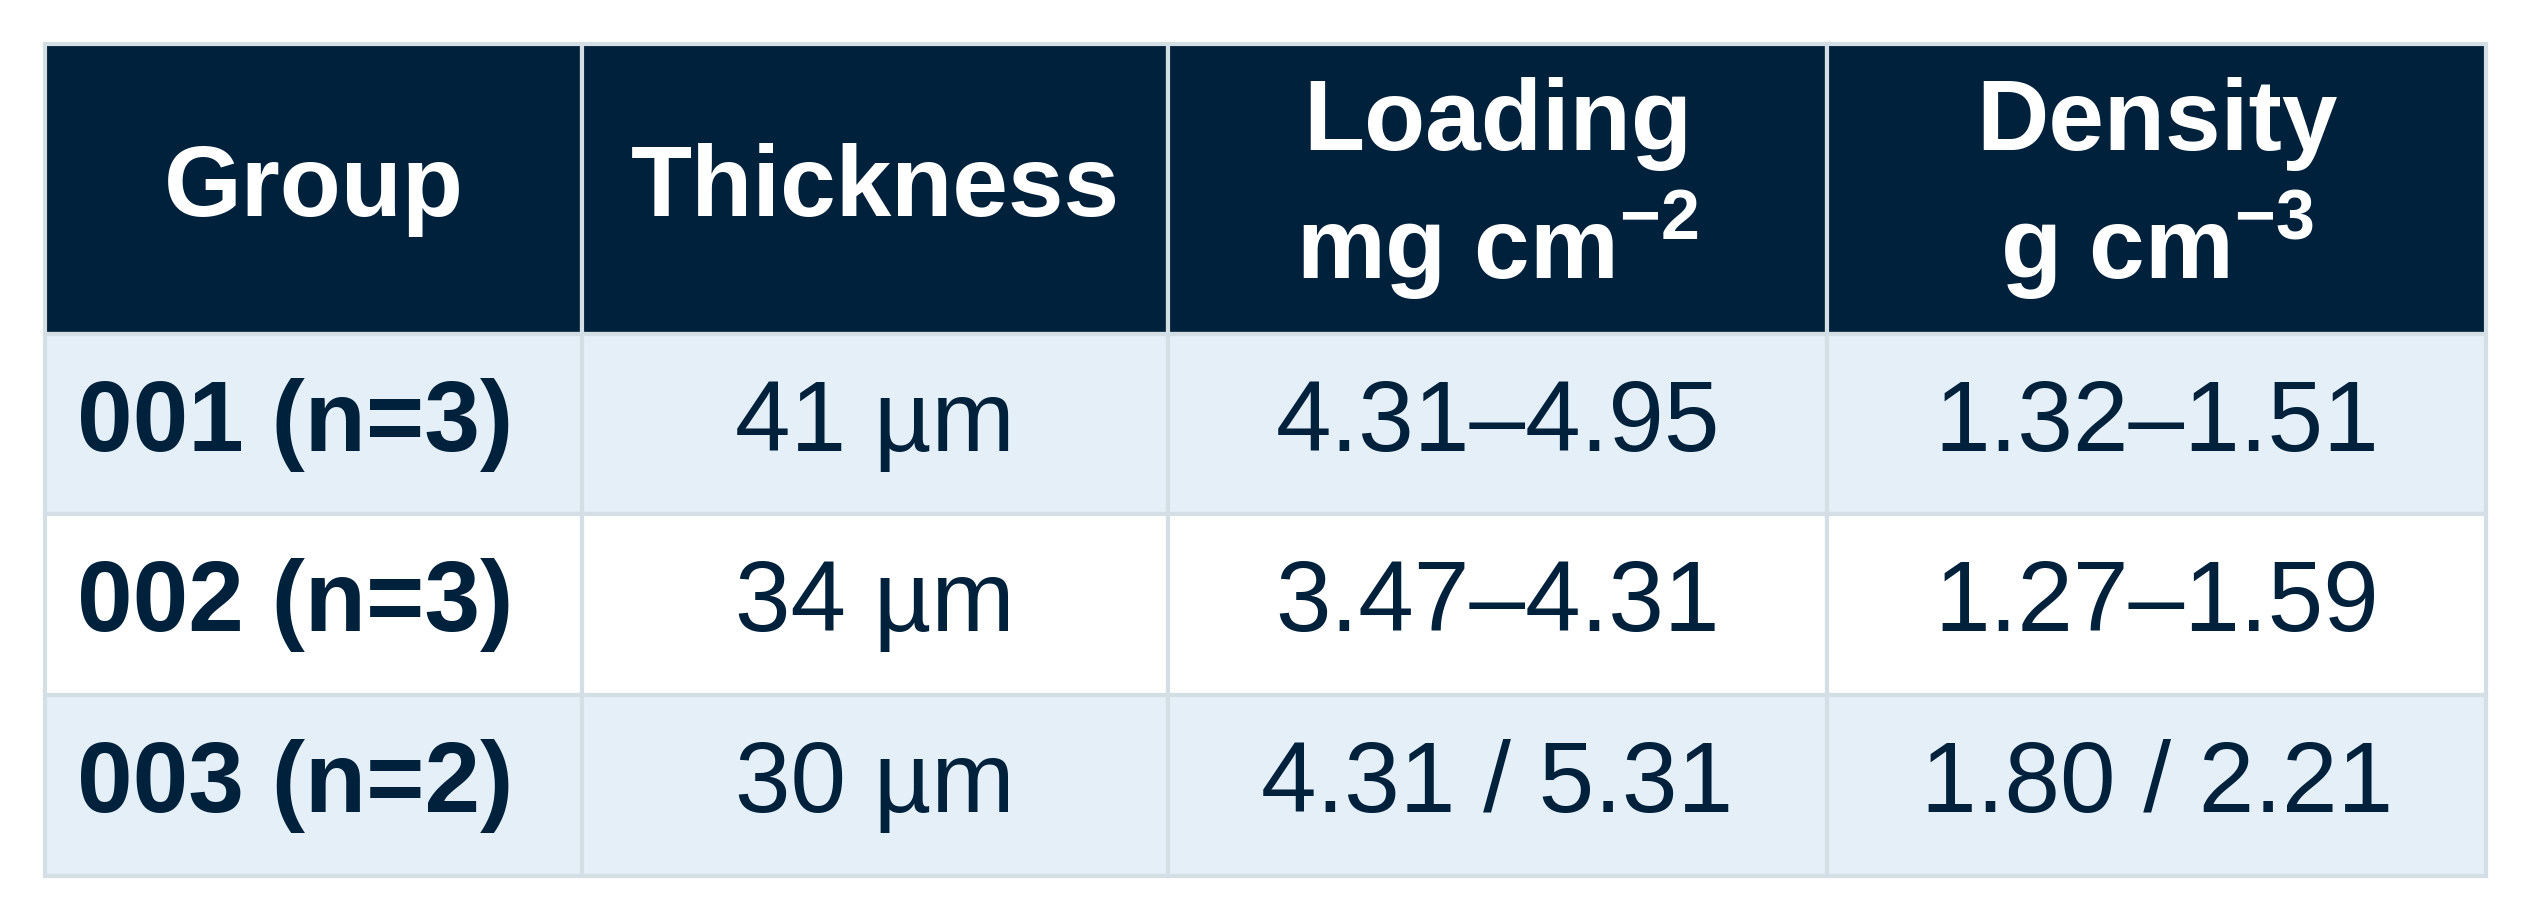

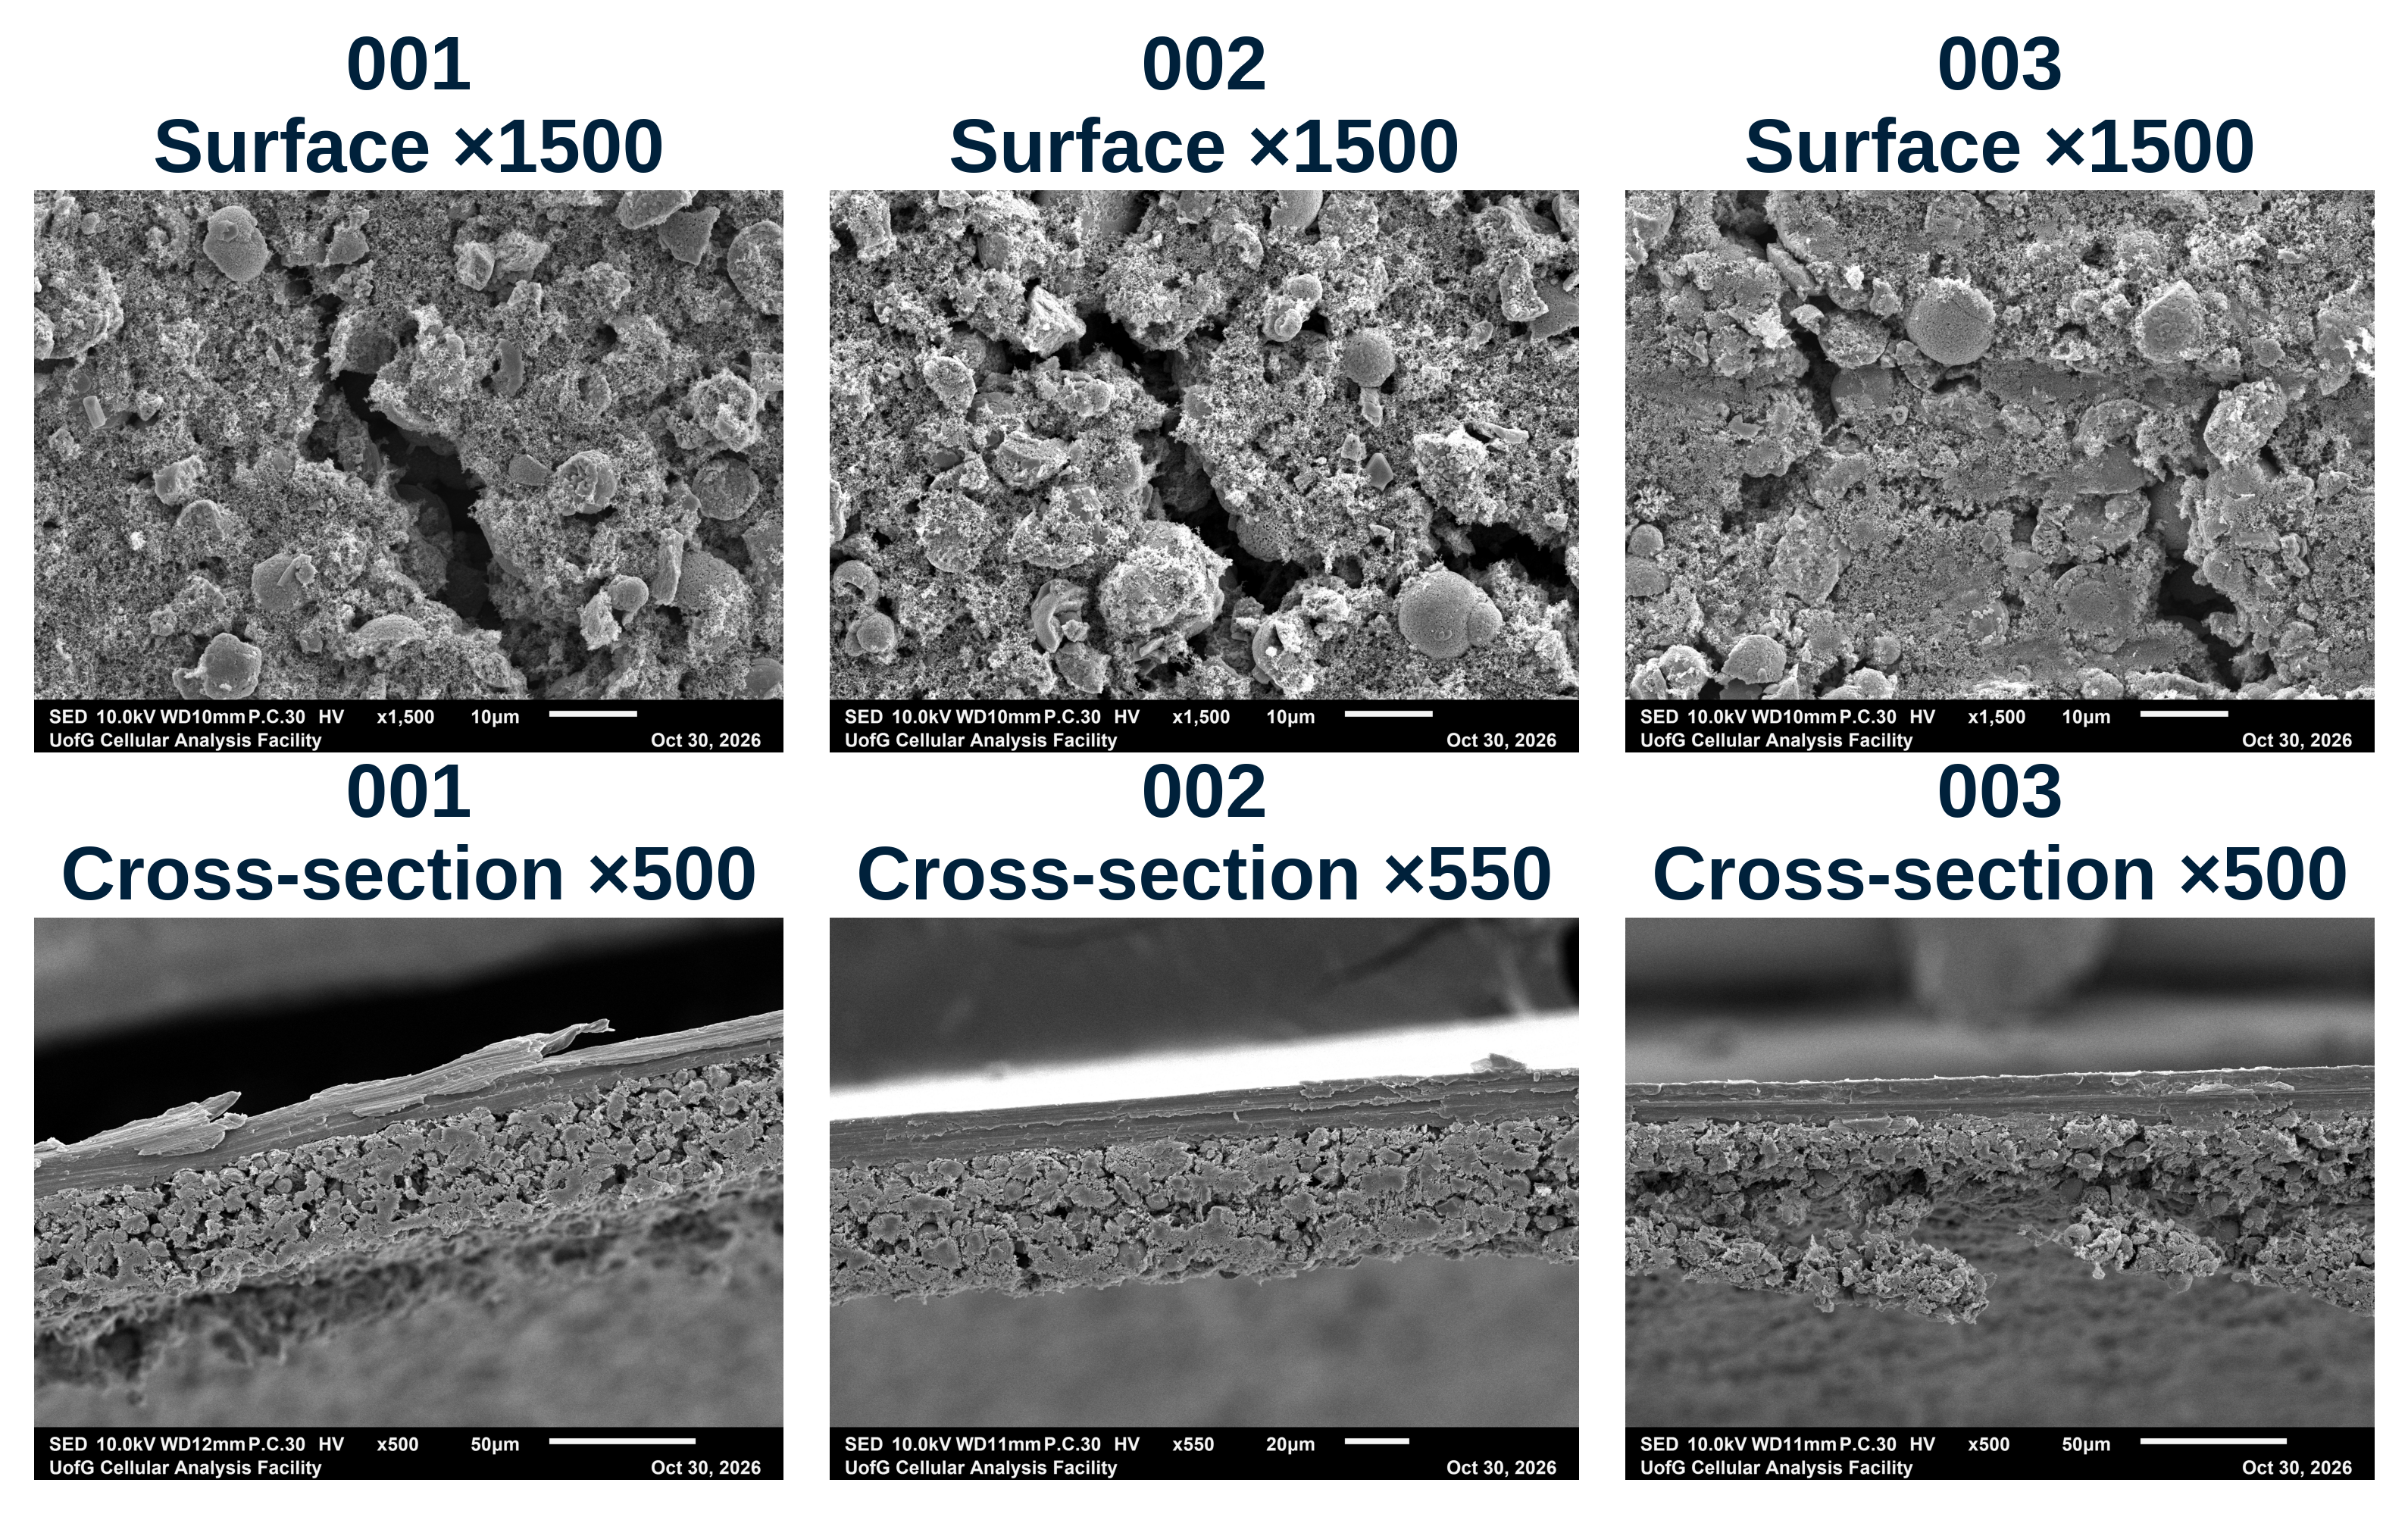

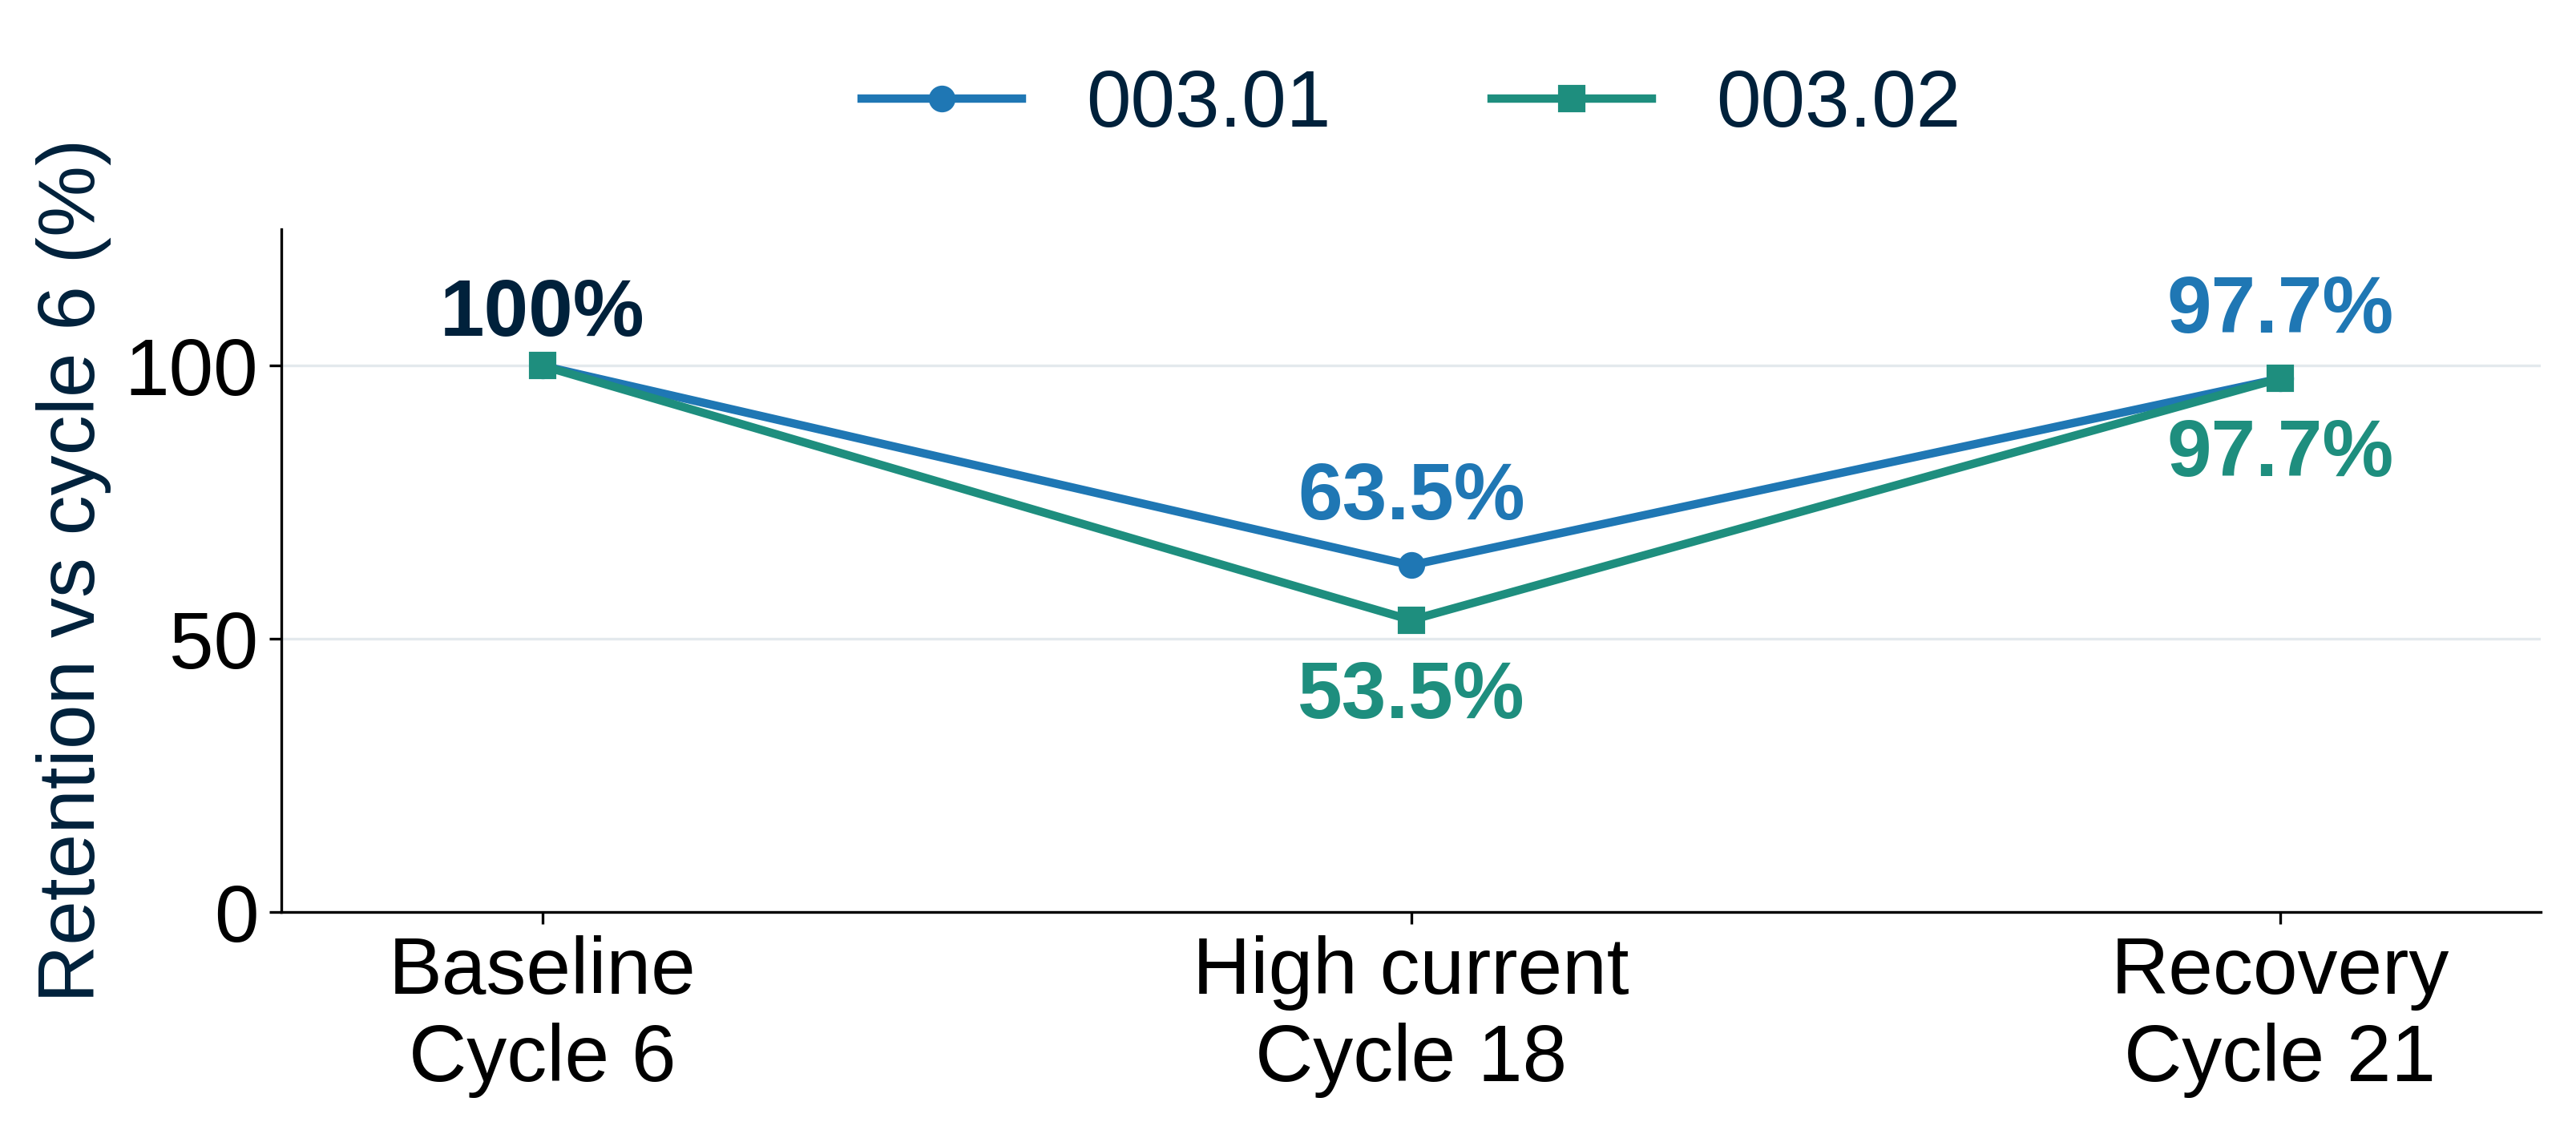

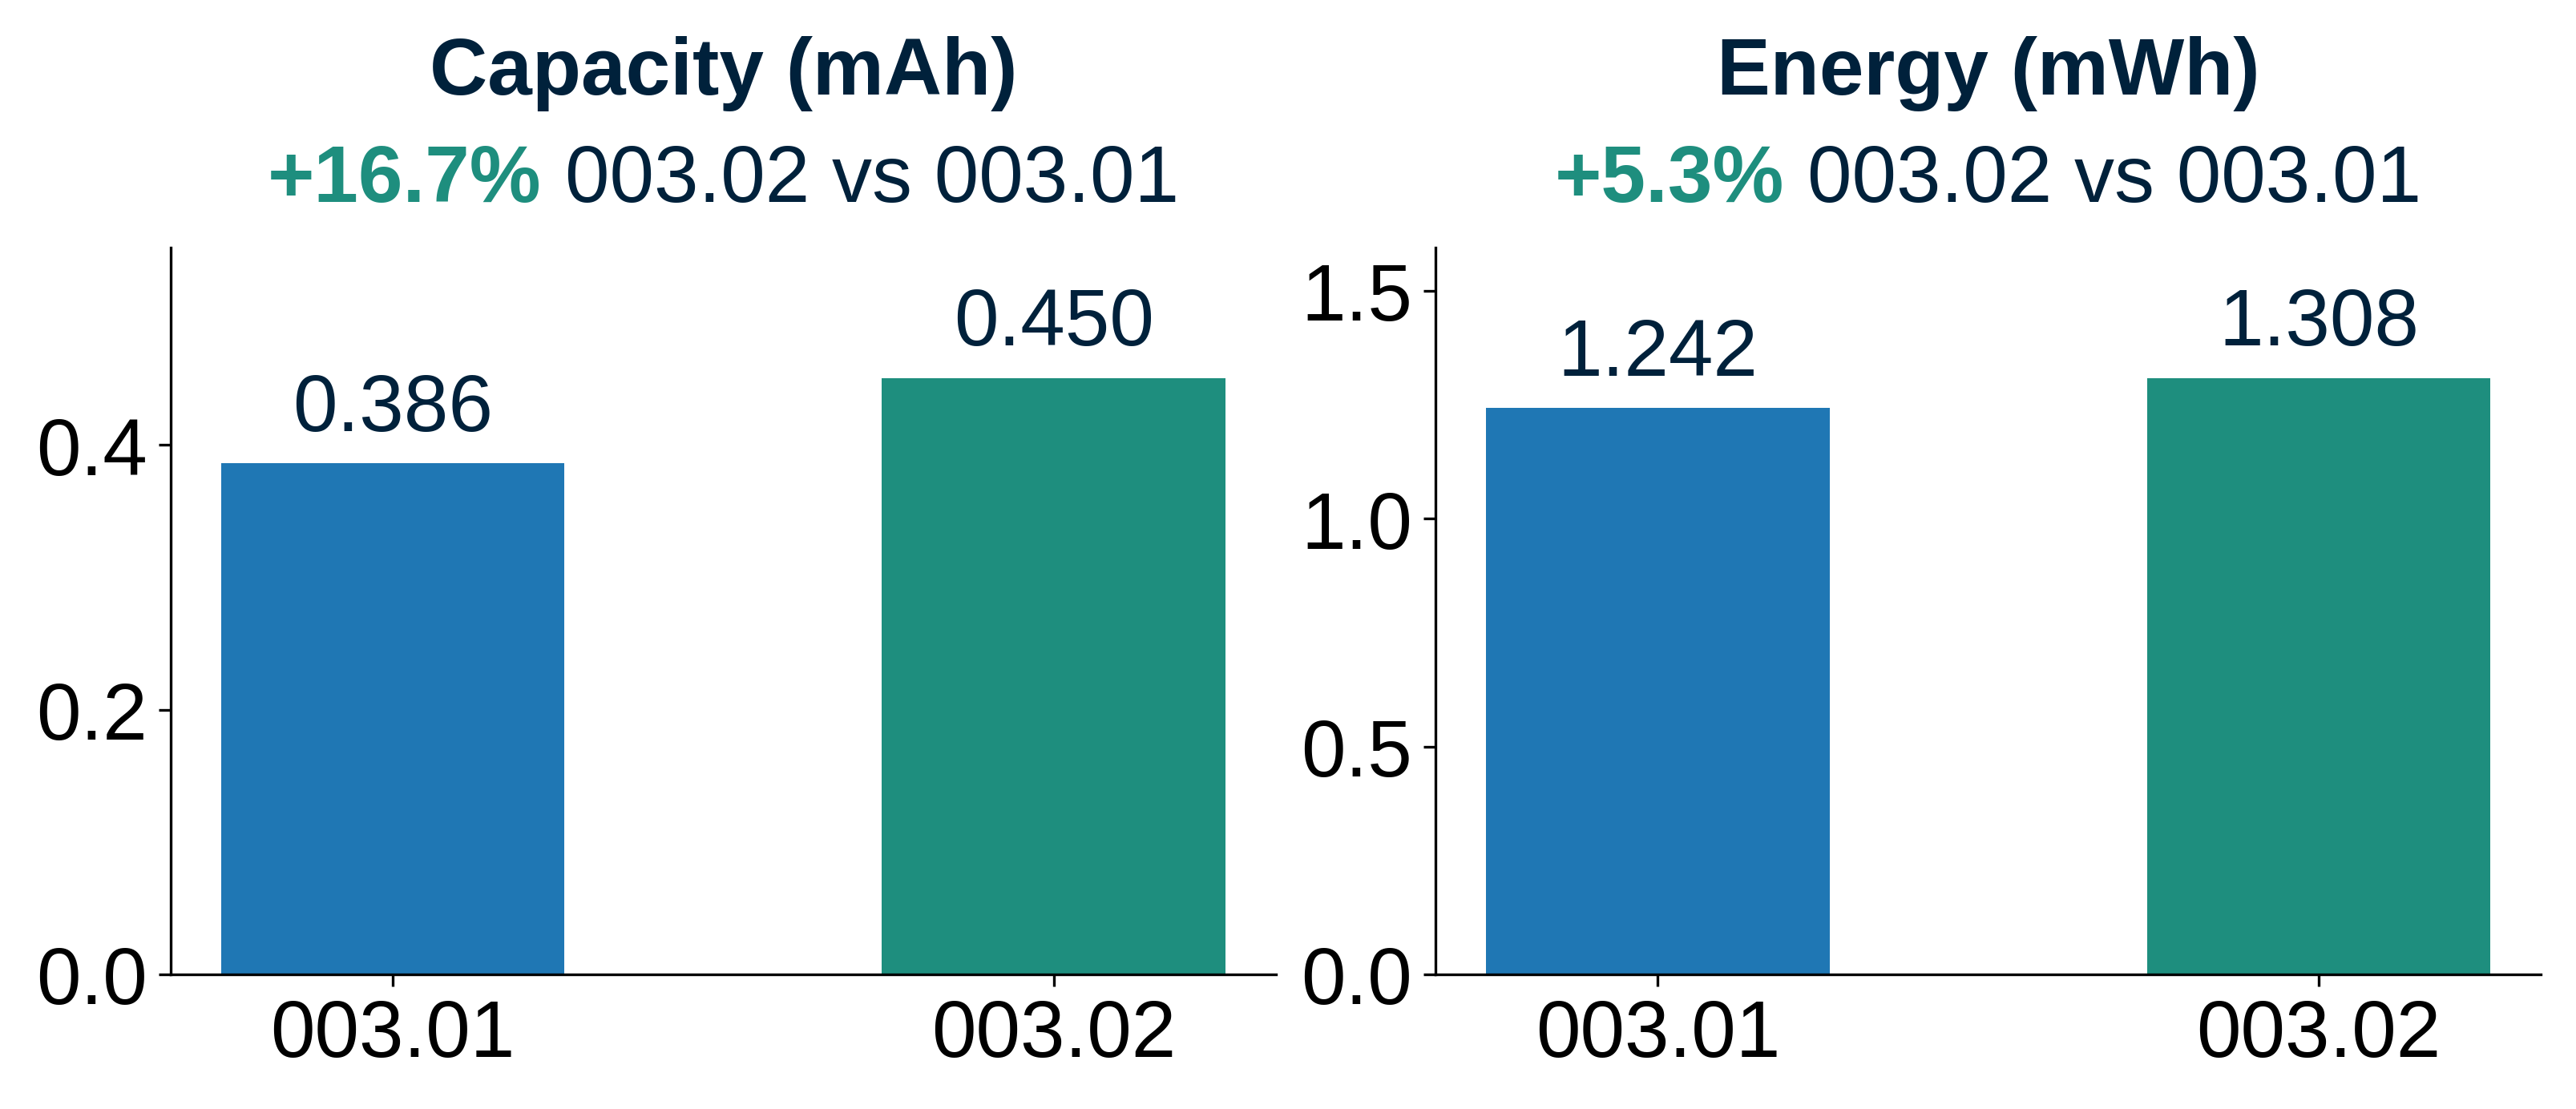

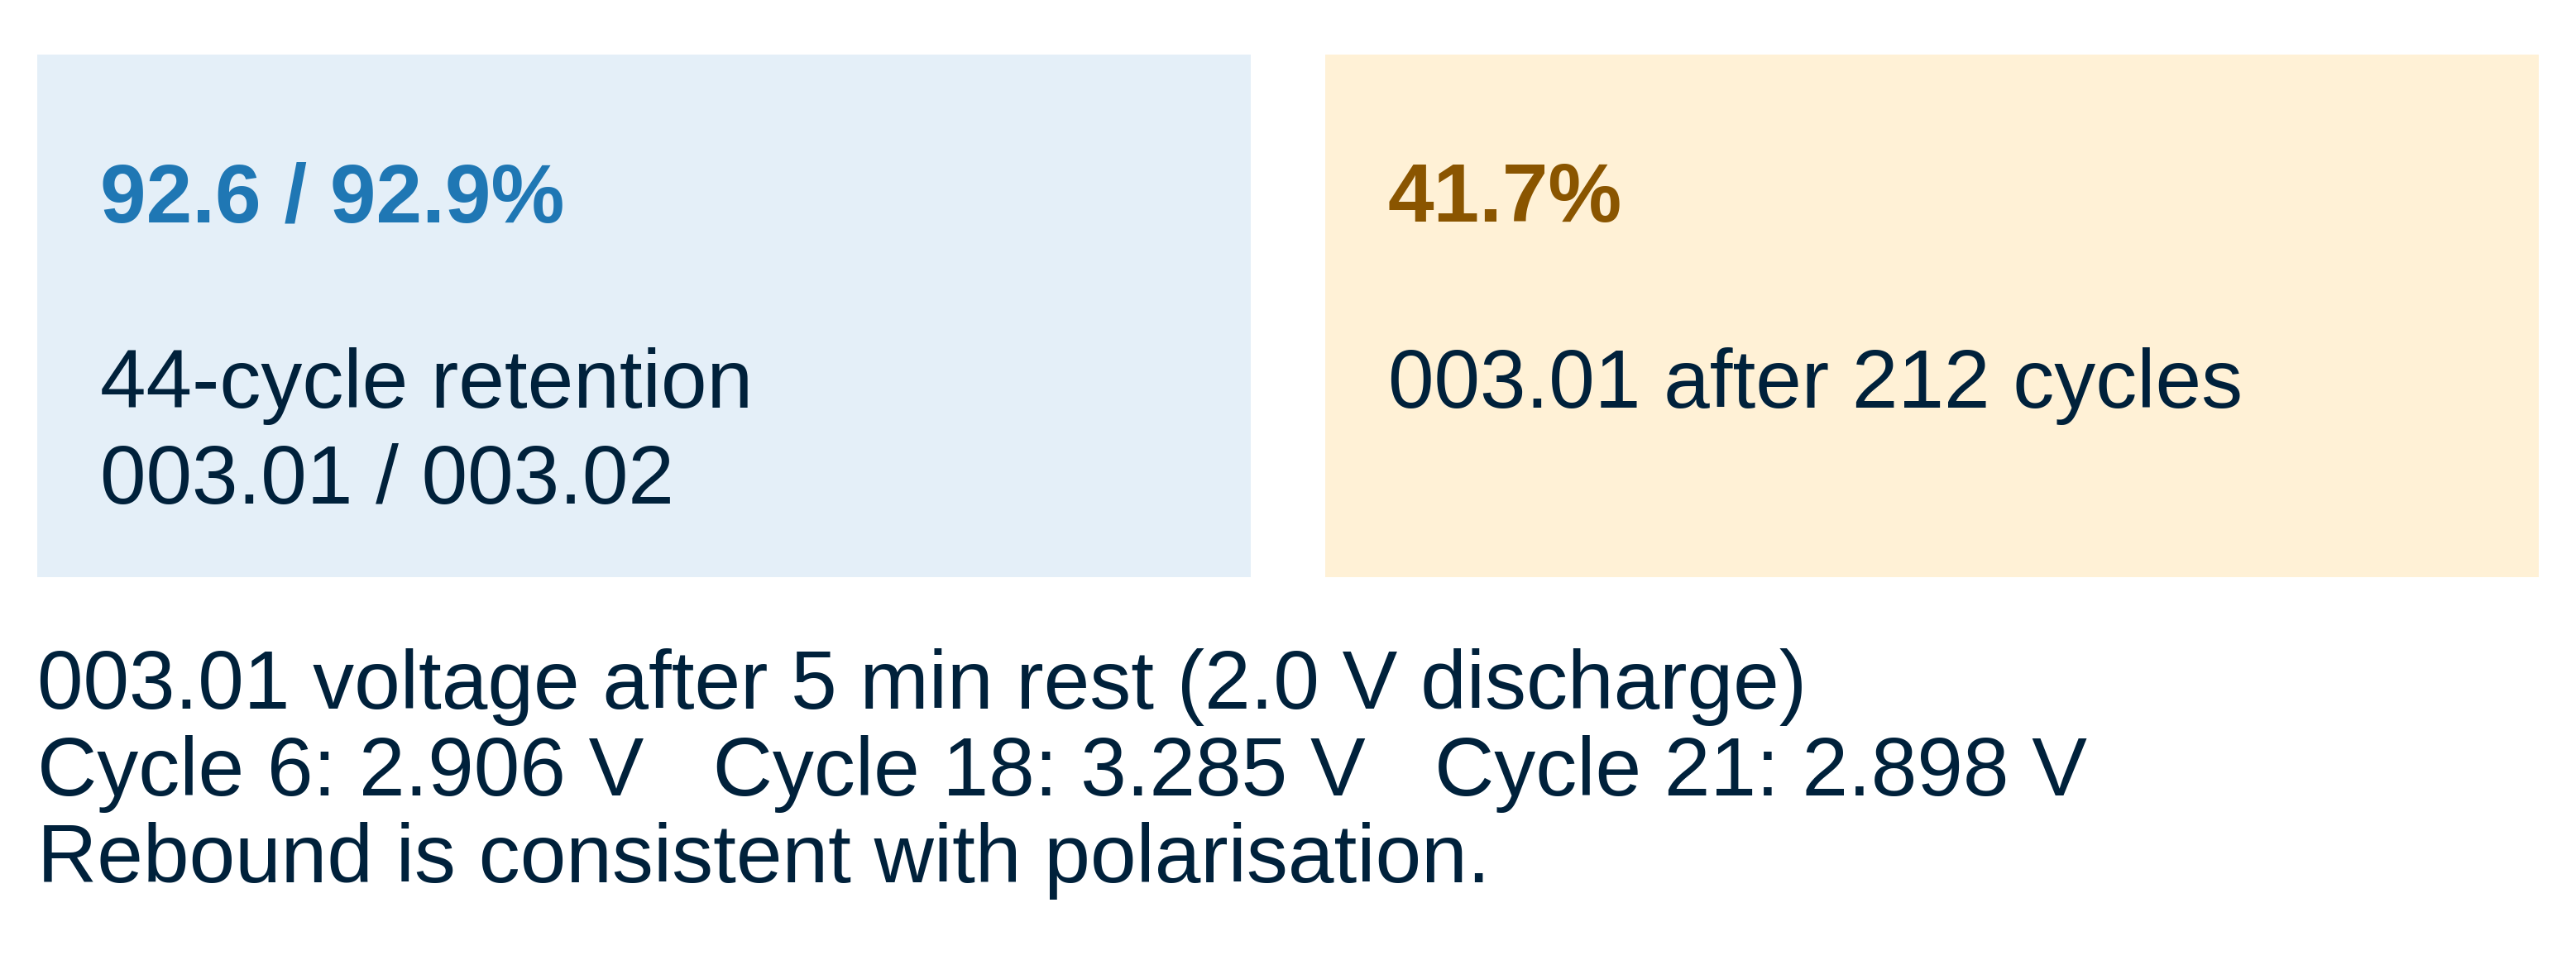

In [5]:
from __future__ import annotations

import argparse
import math
import re
import tempfile
import warnings
from pathlib import Path

import matplotlib

matplotlib.use("Agg")

import matplotlib.pyplot as plt
import openpyxl
import pandas as pd
from matplotlib.offsetbox import AnnotationBbox, HPacker, TextArea
from matplotlib.patches import Rectangle
from PIL import Image

THICKNESS_UM = {"001": 41, "002": 34, "003": 30}
GROUPS = tuple(THICKNESS_UM)
RATE_CELLS = ("003.01", "003.02")
CELLS = ("001.01", "001.02", "001.03", "002.01", "002.02", "002.03", *RATE_CELLS)

DISC_DIAMETER_CM = 1.2
AREA_CM2 = math.pi * (DISC_DIAMETER_CM / 2) ** 2
ACTIVE_FRACTION = 0.80
SPECIFIC_CAPACITY_1C_MA_PER_G = 250.0

CHARGE_CUTOFF_V = 4.8
DISCHARGE_CUTOFF_V = 2.0
VOLTAGE_TOLERANCE_V = 0.01
FIRST_CHARGE_DONE_V = 4.79

COMPARISON_CSV = "003_Performance_Comparison.csv"
CHECKPOINTS = (6, 18, 21)
STAGES = ("Baseline", "High current", "Recovery")
CYCLING_REFERENCE_CYCLE = 22
CYCLING_ENDPOINTS = (("003.01", 65), ("003.02", 65), ("003.01", 233))
REST_SECONDS = 300
SEM_EDGE_MAGNIFICATION = {"001": 500, "002": 550, "003": 500}

NAVY, BLUE, GREEN, AMBER = "#00213B", "#1F77B4", "#1E8E7E", "#8A5500"

warnings.filterwarnings("ignore", message="Workbook contains no default style")

POSTER_FONT = 24
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": POSTER_FONT,
    "axes.titlesize": POSTER_FONT,
    "text.color": NAVY,
    "axes.labelcolor": NAVY,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
})


def _key(name: str) -> str:
    stem = Path(name).stem.casefold()
    stem = re.sub(r"\s*\(\d+\)$", "", stem)
    return re.sub(r"[\s._-]+", "_", stem)


def find_inputs(data_dir: Path) -> dict:
    available = {
        (_key(p.name), p.suffix.casefold()): p
        for p in Path(data_dir).iterdir()
        if p.is_file()
    }
    xlsx, sem, missing = {}, {}, []

    for cell in CELLS:
        path = available.get((_key(f"{cell}.xlsx"), ".xlsx"))
        (xlsx.__setitem__(cell, path) if path else missing.append(f"{cell}.xlsx"))

    for group in GROUPS:
        for kind, stem in (("surface", f"{group}_x1500_1"), ("edge", f"{group}_edge_x500_1")):
            path = available.get((stem, ".tif")) or available.get((stem, ".tiff"))
            (sem.__setitem__((group, kind), path) if path
             else missing.append(f"{stem}.tif"))

    if missing:
        raise FileNotFoundError(
            f"Missing input files in {data_dir}:\n  " + "\n  ".join(missing)
        )
    comparison = Path(data_dir) / COMPARISON_CSV
    if not comparison.is_file():
        raise FileNotFoundError(f"Add {COMPARISON_CSV} from BATCH 2 to {data_dir}.")
    return {"xlsx": xlsx, "sem": sem, "comparison": comparison}


def read_mass_mg(path: Path) -> float:
    workbook = openpyxl.load_workbook(path, read_only=True, data_only=True)
    try:
        sheet = workbook["test"]
        sheet.reset_dimensions()
        for row in sheet.iter_rows(max_row=100, values_only=True):
            for label, value in zip(row, row[2:]):
                if str(label).strip().casefold() != "active material":
                    continue
                match = re.fullmatch(r"\s*(\d+(?:\.\d+)?)\s*mg\s*", str(value), re.I)
                if match and float(match[1]) > 0:
                    return float(match[1])
                raise ValueError(f"{path.name}: invalid active material mass {value!r}.")
    finally:
        workbook.close()
    raise ValueError(f"{path.name}: active material mass was not found on the test sheet.")


def read_steps(path: Path) -> pd.DataFrame:
    workbook = openpyxl.load_workbook(path, read_only=True, data_only=True)
    try:
        sheet = workbook["step"]
        sheet.reset_dimensions()
        rows = iter(sheet.values)
        columns = next(rows)
        return (
            pd.DataFrame(rows, columns=columns)
            .sort_values("Step Number")
            .reset_index(drop=True)
        )
    finally:
        workbook.close()


def completed_discharge(steps: pd.DataFrame, cycle: int) -> pd.Series:
    rows = steps[steps["Cycle Index"].eq(cycle)]
    charge = rows[rows["Step Type"].eq("CC Chg")]
    discharge = rows[rows["Step Type"].eq("CC DChg")]

    for selected, cutoff in ((charge, CHARGE_CUTOFF_V), (discharge, DISCHARGE_CUTOFF_V)):
        if len(selected) != 1:
            raise ValueError(f"Cycle {cycle}: expected one charge and one discharge.")
        row = selected.iloc[0]
        if (
            abs(row["End Voltage(V)"] - cutoff) > VOLTAGE_TOLERANCE_V
            or pd.to_timedelta(row["Step Time"]).total_seconds() < 1
            or row["Capacity(mAh)"] <= 0.0001
        ):
            raise ValueError(f"Cycle {cycle}: step failed the completion checks.")

    return discharge.iloc[0]


def discharge_current_ma(path: Path, step: pd.Series) -> float:
    start, end = str(step["Oneset Date"]), str(step["End Date"])
    workbook = openpyxl.load_workbook(path, read_only=True, data_only=True)
    try:
        sheet = workbook["record"]
        sheet.reset_dimensions()
        rows = sheet.iter_rows(values_only=True)
        header = list(next(rows))
        i_type, i_cur, i_date = (header.index(n) for n in ("Step Type", "Current(mA)", "Date"))
        currents = []
        for row in rows:
            date = str(row[i_date])
            if date > end:
                break
            if row[i_type] == "CC DChg" and start <= date <= end:
                currents.append(abs(row[i_cur]))
    finally:
        workbook.close()
    if not currents:
        raise ValueError(f"{path.name}: no current records found for the discharge step.")
    return float(pd.Series(currents).median())


def coating_volume_cm3(cell: str) -> float:
    return AREA_CM2 * THICKNESS_UM[cell[:3]] * 1e-4


def show_and_save(fig, out: Path, stem: str) -> Path:
    png = out / f"{stem}.png"
    fig.savefig(png, dpi=300, bbox_inches="tight", pad_inches=0.15)
    fig.savefig(out / f"{stem}.pdf", bbox_inches="tight", pad_inches=0.15)
    plt.close(fig)
    return png


def electrode_properties(inputs: dict, out: Path) -> tuple[pd.DataFrame, pd.DataFrame, Path]:
    rows = []
    for cell in CELLS:
        mass = read_mass_mg(inputs["xlsx"][cell])
        rows.append((
            cell,
            THICKNESS_UM[cell[:3]],
            mass,
            mass / AREA_CM2,
            mass / (1000 * ACTIVE_FRACTION * coating_volume_cm3(cell)),
        ))
    by_cell = pd.DataFrame(rows, columns=[
        "Cell", "Thickness (µm)", "Active mass (mg)", "Loading (mg/cm²)", "Density (g/cm³)",
    ])
    by_cell.to_csv(out / "03_electrode_properties_by_cell.csv", index=False)

    def fmt(values, group):
        if group == "003":
            return " / ".join(f"{v:.2f}" for v in values)
        return f"{values.min():.2f}–{values.max():.2f}"

    summary_rows = []
    for group in GROUPS:
        sel = by_cell[by_cell["Cell"].str.startswith(group)]
        summary_rows.append((
            f"{group} (n={len(sel)})", THICKNESS_UM[group],
            fmt(sel["Loading (mg/cm²)"], group), fmt(sel["Density (g/cm³)"], group),
        ))
    summary = pd.DataFrame(summary_rows, columns=[
        "Group", "Thickness (µm)", "Loading (mg/cm²)", "Density (g/cm³)",
    ])
    summary.to_csv(out / "03_electrode_properties.csv", index=False)

    display_rows = [
        (row["Group"], f"{row['Thickness (µm)']} µm", row["Loading (mg/cm²)"], row["Density (g/cm³)"])
        for _, row in summary.iterrows()
    ]
    fig, ax = plt.subplots(figsize=(10.5, 3.6))
    ax.set_axis_off()
    table = ax.table(
        cellText=display_rows,
        colLabels=["Group", "Thickness", "Loading\nmg cm$^{\\mathregular{-2}}$", "Density\ng cm$^{\\mathregular{-3}}$"],
        colWidths=[0.22, 0.24, 0.27, 0.27], cellLoc="center", bbox=(0, 0, 1, 1),
    )
    table.auto_set_font_size(False)
    table.set_fontsize(POSTER_FONT)
    for (row, column), cell in table.get_celld().items():
        cell.set_edgecolor("#D3DFE5")
        if row == 0:
            cell.set_height(cell.get_height() * 1.6)
            cell.set_facecolor(NAVY)
            cell.set_text_props(color="white", weight="bold")
        else:
            cell.set_facecolor("#E4EFF8" if row % 2 else "white")
            if column == 0:
                cell.set_text_props(weight="bold", ha="left")
                cell.PAD = 0.06
    png = show_and_save(fig, out, "03_electrode_properties")
    return by_cell, summary, png


def draw_sem(inputs: dict, out: Path) -> Path:
    fig, axes = plt.subplots(2, 3, figsize=(10.5, 6.4), layout="constrained")
    for column, group in enumerate(GROUPS):
        panels = (
            (inputs["sem"][(group, "surface")], "Surface ×1500"),
            (inputs["sem"][(group, "edge")], f"Cross-section ×{SEM_EDGE_MAGNIFICATION[group]}"),
        )
        for row, (path, label) in enumerate(panels):
            ax = axes[row, column]
            with Image.open(path) as image:
                ax.imshow(image.convert("RGB"))
            ax.set_box_aspect(0.75)
            ax.set_title(f"{group}\n{label}", fontsize=POSTER_FONT, weight="bold", pad=6)
            ax.set_axis_off()
    return show_and_save(fig, out, "03_sem")


def first_charge_table(inputs: dict, out: Path) -> pd.DataFrame:
    rows = []
    for cell in CELLS:
        steps = read_steps(inputs["xlsx"][cell])
        charge = steps[steps["Step Type"].eq("CC Chg")].iloc[0]
        hours = pd.to_timedelta(charge["Step Time"]).total_seconds() / 3600
        reached = charge["End Voltage(V)"] >= FIRST_CHARGE_DONE_V
        rows.append((
            cell, round(hours, 1), round(float(charge["End Voltage(V)"]), 2), bool(reached),
            int(steps["Cycle Index"].max()),
        ))
    table = pd.DataFrame(rows, columns=[
        "Cell", "First charge (h)", "Voltage at end of first charge (V)",
        "Reached 4.8 V cut-off", "Last cycle index in file",
    ])
    table.to_csv(out / "04_first_charge.csv", index=False)
    return table


def performance_values(inputs: dict, steps: dict, out: Path) -> pd.DataFrame:
    path = inputs["comparison"]
    columns = {
        "capacity_retention_percent_cycle18_vs6": "Cycle 18 retention (%)",
        "capacity_recovery_percent_cycle21_vs6": "Cycle 21 recovery (%)",
        "discharge_mAh_cycle18": "Charge (mAh)",
        "discharge_energy_mWh_cycle18": "Energy (mWh)",
        "volumetric_capacity_mAh_cm3_cycle18": "Charge (mAh/cm³)",
        "volumetric_energy_mWh_cm3_cycle18": "Energy (mWh/cm³)",
        "actual_discharge_C_cycle18": "Cycle 18 actual rate (C)",
    }
    source = pd.read_csv(path, dtype={"cell": str})
    missing = {"cell", *columns}.difference(source.columns)
    if missing:
        raise ValueError(f"{path.name}: missing columns: {', '.join(sorted(missing))}")
    source = source[source["cell"].isin(RATE_CELLS)]
    if len(source) != len(RATE_CELLS) or set(source["cell"]) != set(RATE_CELLS):
        raise ValueError(f"{path.name}: expected one row each for 003.01 and 003.02.")

    values = source.set_index("cell").loc[list(RATE_CELLS), list(columns)]
    values = values.apply(pd.to_numeric, errors="raise")
    if not all(math.isfinite(value) and value > 0 for value in values.to_numpy().flat):
        raise ValueError(f"{path.name}: the comparison values must be finite and positive.")
    values = values.rename(columns=columns).rename_axis("Cell").reset_index()

    # The Batch 2 comparison CSV reports actual C-rate but omits current in mA.
    values.insert(7, "Cycle 18 discharge current (mA)", [
        discharge_current_ma(inputs["xlsx"][cell], completed_discharge(steps[cell], 18))
        for cell in RATE_CELLS
    ])
    values.to_csv(out / "05_06_performance_values.csv", index=False)
    return values


def draw_section_5(values: pd.DataFrame, out: Path) -> Path:
    fig, ax = plt.subplots(figsize=(10.5, 4.5), layout="constrained")
    for index, row in values.iterrows():
        points = (100, row["Cycle 18 retention (%)"], row["Cycle 21 recovery (%)"])
        color = (BLUE, GREEN)[index]
        offset = (20, -23)[index]
        ax.plot(range(3), points, marker=("o", "s")[index], lw=2.5,
                color=color, label=row["Cell"], markersize=7)
        for x in (1, 2):
            ax.annotate(f"{points[x]:.1f}%", (x, points[x]), xytext=(0, offset),
                        textcoords="offset points", ha="center", va="center",
                        color=color, weight="bold")
    ax.annotate("100%", (0, 100), xytext=(0, 9), textcoords="offset points",
                ha="center", weight="bold")
    ax.set(
        xticks=range(3),
        xticklabels=[f"{s}\nCycle {c}" for s, c in zip(STAGES, CHECKPOINTS)],
        ylabel="Retention vs cycle 6 (%)", ylim=(0, 125), xlim=(-0.30, 2.30),
    )
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=False)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#E3E9ED")
    return show_and_save(fig, out, "05_capacity_retention_recovery")


def draw_section_6(values: pd.DataFrame, out: Path) -> Path:
    values = values.set_index("Cell").loc[list(RATE_CELLS)]
    metrics = (("Charge (mAh)", "Charge (mAh/cm³)"), ("Energy (mWh)", "Energy (mWh/cm³)"))
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4), layout="constrained")
    for ax, (total, per_volume) in zip(axes, metrics):
        gain = 100 * (values.at["003.02", per_volume] / values.at["003.01", per_volume] - 1)
        bars = ax.bar(values.index, values[total], color=[BLUE, GREEN], width=0.52)
        caption = HPacker(
            children=[
                TextArea(f"{gain:+.1f}%", textprops={"color": GREEN, "fontsize": POSTER_FONT, "weight": "bold"}),
                TextArea("003.02 vs 003.01", textprops={"color": NAVY, "fontsize": POSTER_FONT}),
            ],
            align="baseline", pad=0, sep=7,
        )
        ax.add_artist(AnnotationBbox(caption, (0.5, 1.04), xycoords="axes fraction",
                                     box_alignment=(0.5, 0), frameon=False, pad=0,
                                     annotation_clip=False))
        title = (
            "Capacity (mAh)"
            if total == "Charge (mAh)"
            else "Energy (mWh)"
        )
        ax.set_title(title, color=NAVY, weight="bold", pad=46)
        ax.set_ylim(0, values[total].max() * 1.22)
        ax.bar_label(bars, fmt="%.3f", padding=5, color=NAVY)
    return show_and_save(fig, out, "06_charge_energy_comparison")


def cycling_and_rebound(steps: dict, out: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    baseline = {
        cell: completed_discharge(steps[cell], CYCLING_REFERENCE_CYCLE)["Capacity(mAh)"]
        for cell in RATE_CELLS
    }
    rows = []
    for cell, cycle in CYCLING_ENDPOINTS:
        capacity = completed_discharge(steps[cell], cycle)["Capacity(mAh)"]
        rows.append((cell, cycle, cycle - 21, 100 * capacity / baseline[cell]))
    cycling = pd.DataFrame(rows, columns=[
        "Cell", "Overall cycle", "Subsequent cycles", "Retention vs cycle 22 (%)",
    ])
    cycling.to_csv(out / "07_cycling_summary.csv", index=False, float_format="%.2f")

    reference = steps[RATE_CELLS[0]]
    rebound_rows = []
    for cycle, stage in zip(CHECKPOINTS, STAGES):
        discharge = completed_discharge(reference, cycle)
        following = discharge.name + 1
        if following >= len(reference):
            raise ValueError(f"Cycle {cycle}: post-discharge rest step is missing.")
        rest = reference.iloc[following]
        if (rest["Cycle Index"] != cycle or rest["Step Type"] != "Rest"
                or pd.to_timedelta(rest["Step Time"]).total_seconds() != REST_SECONDS):
            raise ValueError(f"Cycle {cycle}: expected a {REST_SECONDS // 60}-minute post-discharge rest.")
        rebound_rows.append((cycle, stage, float(rest["End Voltage(V)"])))
    rebound = pd.DataFrame(rebound_rows, columns=[
        "Overall cycle", "Stage", "Voltage after 5 min rest (V)",
    ])
    rebound.to_csv(out / "07_voltage_rebound.csv", index=False, float_format="%.3f")
    return cycling, rebound


def draw_section_7(cycling: pd.DataFrame, rebound: pd.DataFrame, out: Path) -> Path:
    ret = cycling.set_index(["Cell", "Subsequent cycles"])["Retention vs cycle 22 (%)"]
    first, second = ret.at[("003.01", 44)], ret.at[("003.02", 44)]
    long_run = ret.at[("003.01", 212)]
    volt = rebound.set_index("Overall cycle")["Voltage after 5 min rest (V)"]

    fig, ax = plt.subplots(figsize=(10.5, 3.8))
    fig.subplots_adjust(left=0.02, right=0.98, bottom=0.03, top=0.97)
    ax.set_axis_off()
    cards = (
        (0.00, "#E4EFF8", BLUE, f"{first:.1f} / {second:.1f}%", "44-cycle retention\n003.01 / 003.02"),
        (0.515, "#FFF1D6", AMBER, f"{long_run:.1f}%", "003.01 after 212 cycles"),
    )
    for x, background, color, value, label in cards:
        ax.add_patch(Rectangle((x, 0.39), 0.485, 0.59, transform=ax.transAxes,
                               facecolor=background, edgecolor="none"))
        ax.text(x + 0.025, 0.86, value, transform=ax.transAxes, fontsize=POSTER_FONT,
                weight="bold", color=color, va="top")
        ax.text(x + 0.025, 0.65, label, transform=ax.transAxes, fontsize=POSTER_FONT,
                color=NAVY, va="top", linespacing=1.3)
    ax.text(
        0.00, 0.31,
        "003.01 voltage after 5 min rest (2.0 V discharge)\n"
        f"Cycle 6: {volt.at[6]:.3f} V   Cycle 18: {volt.at[18]:.3f} V   "
        f"Cycle 21: {volt.at[21]:.3f} V\n"
        "Rebound is consistent with polarisation.",
        transform=ax.transAxes, fontsize=POSTER_FONT, color=NAVY, va="top", linespacing=1.15,
    )
    return show_and_save(fig, out, "07_cycling_and_voltage_rebound")


def write_poster_numbers(by_cell, values, first_charge, cycling, rebound, out: Path) -> pd.DataFrame:
    v = values.set_index("Cell")
    rows = []

    def add(section, quantity, value, unit=""):
        rows.append((section, quantity, value, unit))

    base = THICKNESS_UM["001"]
    for g in ("002", "003"):
        add("3", f"Thickness change {g} vs 001", 100 * (THICKNESS_UM[g] / base - 1), "%")
    for cell in RATE_CELLS:
        add("5", f"{cell} retention, cycle 18 / cycle 6", v.at[cell, "Cycle 18 retention (%)"], "%")
        add("5", f"{cell} recovery, cycle 21 / cycle 6", v.at[cell, "Cycle 21 recovery (%)"], "%")
        add("5", f"{cell} cycle 18 discharge current", v.at[cell, "Cycle 18 discharge current (mA)"], "mA")
        add("5", f"{cell} cycle 18 actual rate", v.at[cell, "Cycle 18 actual rate (C)"], "C")
        add("6", f"{cell} charge, cycle 18", v.at[cell, "Charge (mAh)"], "mAh")
        add("6", f"{cell} energy, cycle 18", v.at[cell, "Energy (mWh)"], "mWh")
    for col, name in (("Charge (mAh/cm³)", "charge"), ("Energy (mWh/cm³)", "energy")):
        add("6", f"Gain in {name} per volume, 003.02 vs 003.01",
            100 * (v.at["003.02", col] / v.at["003.01", col] - 1), "%")
    for _, r in cycling.iterrows():
        add("7", f"{r['Cell']} retention after {r['Subsequent cycles']} cycles", r["Retention vs cycle 22 (%)"], "%")
    for _, r in rebound.iterrows():
        add("7", f"003.01 voltage after rest, cycle {r['Overall cycle']}", r["Voltage after 5 min rest (V)"], "V")
    for _, r in first_charge.iterrows():
        add("4", f"{r['Cell']} first charge duration", r["First charge (h)"], "h")
    table = pd.DataFrame(rows, columns=["Poster section", "Quantity", "Value", "Unit"])
    table.to_csv(out / "poster_numbers.csv", index=False, float_format="%.4f")
    return table


def run(data_dir: Path, out_dir: Path) -> list[Path]:
    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)
    inputs = find_inputs(Path(data_dir))
    print(f"Found {len(inputs['xlsx'])} Excel files and {len(inputs['sem'])} SEM images.")

    steps = {cell: read_steps(inputs["xlsx"][cell]) for cell in RATE_CELLS}
    values = performance_values(inputs, steps, out)
    by_cell, _, table_png = electrode_properties(inputs, out)
    figures = [table_png, draw_sem(inputs, out)]
    first_charge = first_charge_table(inputs, out)
    figures.append(draw_section_5(values, out))
    figures.append(draw_section_6(values, out))
    cycling, rebound = cycling_and_rebound(steps, out)
    figures.append(draw_section_7(cycling, rebound, out))
    write_poster_numbers(by_cell, values, first_charge, cycling, rebound, out)

    print(f"PNG, PDF and CSV files saved to {out.resolve()}")
    return figures


def run_colab(out_dir: str = "/content/poster_figures") -> list[Path]:
    from google.colab import files

    with tempfile.TemporaryDirectory(prefix="poster_inputs_") as folder:
        print(f"Please upload all 8 battery Excel files, 6 SEM TIFF images, and {COMPARISON_CSV}.")
        for filename, content in files.upload().items():
            (Path(folder) / Path(filename).name).write_bytes(content)
        return run(Path(folder), Path(out_dir))


def main(argv=None) -> None:
    parser = argparse.ArgumentParser(description="Poster figures and numbers for the Li-rich cathode rate study")
    parser.add_argument("--data-dir", type=Path, default=Path("data"),
                        help="folder with the 8 .xlsx files, 6 SEM TIFF images, and the BATCH 2 comparison CSV")
    parser.add_argument("--out", type=Path, default=Path("poster_figures"),
                        help="folder for figures and CSV tables")
    args = parser.parse_args(argv)
    run(args.data_dir, args.out)

if __name__ == "__main__":
    import sys

    if "google.colab" in sys.modules:
        from IPython.display import Image as DisplayImage, display

        for path in run_colab():
            display(DisplayImage(filename=str(path), width=800))
    else:
        main()





In [6]:
!zip -qr poster_figures.zip /content/poster_figures
from google.colab import files
files.download("poster_figures.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>